<a href="https://colab.research.google.com/github/Jacquou2/Data_mining_project/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Τελική Εργασία

*Γιώργος Δρακούλης 57785*

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
from torchsummary import summary

Κατεβάζουμε τα δεδομένα

In [ ]:
batch_size = 10

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transforms.ToTensor())
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transforms.ToTensor())
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)

Files already downloaded and verified
Files already downloaded and verified


## Ορίζουμε την αρχιτεκτονική του δικτύου

In [ ]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 3)
        self.fc1 = nn.Linear(64 * 6 * 6, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        #x = F.relu(self.fc2(x))
        x = self.fc2(x)
        return x


net = Net()

Παρακάτω φαίνεται η δομή του δικτύου. Παρατηρούμε οτι οι συνολικοί παράμετροι το δικτύου είναι 315.722

In [ ]:
if torch.cuda.is_available():
  summary(net.cuda() , (3,32,32))
else:
  summary(net , (3,32,32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 30, 30]             896
         MaxPool2d-2           [-1, 32, 15, 15]               0
            Conv2d-3           [-1, 64, 13, 13]          18,496
         MaxPool2d-4             [-1, 64, 6, 6]               0
            Linear-5                  [-1, 128]         295,040
            Linear-6                   [-1, 10]           1,290
Total params: 315,722
Trainable params: 315,722
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.38
Params size (MB): 1.20
Estimated Total Size (MB): 1.59
----------------------------------------------------------------


Ορίζουμε τον αριθμό εποχών,το learning rate,τον optimizer και το loss function για την εκπαίδευση

In [ ]:
learning_rate = 0.001
num_epochs = 6

if torch.cuda.is_available():
  model = net.cuda()
else:
  model = net

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

Ορίζουμε τις συναρτήσεις εκπαίδευσης και δοκιμής των δεδομένων

In [ ]:
def train_loop(train_loader,model,loss_fn,optimizer,epoch):
  loss_array = []
  running_loss = 0
  print_var = 10000/batch_size
  for i, data in enumerate(train_loader):

        inputs, labels = data
        if torch.cuda.is_available():
         inputs, labels = inputs.cuda(), labels.cuda()

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

  return running_loss/i

def test_loop(test_loader,model):
  total,correct = 0,0
  with torch.no_grad():
    for data in test_loader:

        images, labels = data
        if torch.cuda.is_available():
         images, labels = images.cuda(), labels.cuda()

        # calculate outputs by running images through the network
        outputs = model(images)

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        test_acc = 100 * correct // total

  print(f'Accuracy of the network on the 10000 test images: {test_acc} %')
  return test_acc

Εκπαιδεύουμε το δίκτυο. Παράλληλα με την εκπαίδευση βλέπουμε και την ακρίβεια του δικτύου στα δεδομένα δοκιμής.

In [ ]:
test_acc_list = []
train_loss_list = []
for t in range(num_epochs):
  print(f"\nEpoch {t+1}\n-------------------------------")
  loss = train_loop(trainloader,model,loss_fn,optimizer,t)
  acc = test_loop(testloader,model)

  train_loss_list.append(loss)
  test_acc_list.append(acc)


Epoch 1
-------------------------------
Accuracy of the network on the 10000 test images: 44 %

Epoch 2
-------------------------------
Accuracy of the network on the 10000 test images: 53 %

Epoch 3
-------------------------------
Accuracy of the network on the 10000 test images: 58 %

Epoch 4
-------------------------------
Accuracy of the network on the 10000 test images: 63 %

Epoch 5
-------------------------------
Accuracy of the network on the 10000 test images: 65 %

Epoch 6
-------------------------------
Accuracy of the network on the 10000 test images: 66 %


Παρακάτω φαίνεται το διάγραμμα κόστους/εποχών και το διάγραμμα test accuracy/εποχών

<function matplotlib.pyplot.show(*args, **kw)>

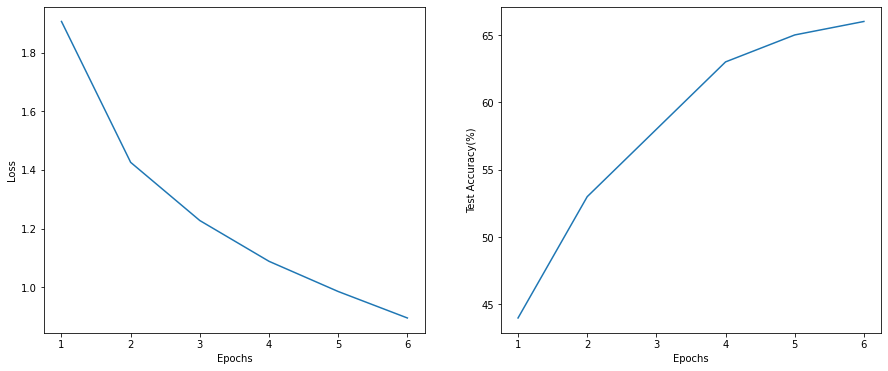

In [ ]:
plt.figure(figsize=(15,6))
plt.subplot(1, 2, 1)
plt.plot(range(1,len(train_loss_list)+1),train_loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")


plt.subplot(1, 2, 2)
plt.plot(range(1,num_epochs+1),test_acc_list)
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

## Δημιουργούμε νέο δίκτυο με batch normalization επίπεδο μετά από κάθε συνελικτικό επίπεδο

In [ ]:
class Net_bn(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3)
        self.conv1_bn = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 3)
        self.conv2_bn = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 6 * 6, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1_bn(self.conv1(x))))
        x = self.pool(F.relu(self.conv2_bn(self.conv2(x))))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


net_bn = Net_bn()

Ορίζουμε τον αριθμό εποχών,το learning rate,τον optimizer και το loss function για την εκπαίδευση. Οι παράμετροι είναι ίδιοι με τις παραμέτρους του προηγούμενου δικτύου ώστε να μπορει να γίνει η σύγκριση μεταξύ των δύο δικτύων.

In [ ]:
learning_rate = 0.001
num_epochs = 6

if torch.cuda.is_available():
  model = net_bn.cuda()
else:
  model = net_bn

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(net_bn.parameters(), lr=learning_rate, momentum=0.9)

Εκπαιδεύουμε το δίκτυο

In [ ]:
test_acc_list = []
train_loss_list = []
for t in range(num_epochs):
  print(f"\nEpoch {t+1}\n-------------------------------")
  loss = train_loop(trainloader,net_bn,loss_fn,optimizer,t)
  acc = test_loop(testloader,net_bn)

  train_loss_list.append(loss)
  test_acc_list.append(acc)


Epoch 1
-------------------------------
Accuracy of the network on the 10000 test images: 61 %

Epoch 2
-------------------------------
Accuracy of the network on the 10000 test images: 66 %

Epoch 3
-------------------------------
Accuracy of the network on the 10000 test images: 68 %

Epoch 4
-------------------------------
Accuracy of the network on the 10000 test images: 69 %

Epoch 5
-------------------------------
Accuracy of the network on the 10000 test images: 70 %

Epoch 6
-------------------------------
Accuracy of the network on the 10000 test images: 72 %


Παρακάτω φαίνεται το διάγραμμα κόστους/εποχών και το διάγραμμα test accuracy/εποχών

<function matplotlib.pyplot.show(*args, **kw)>

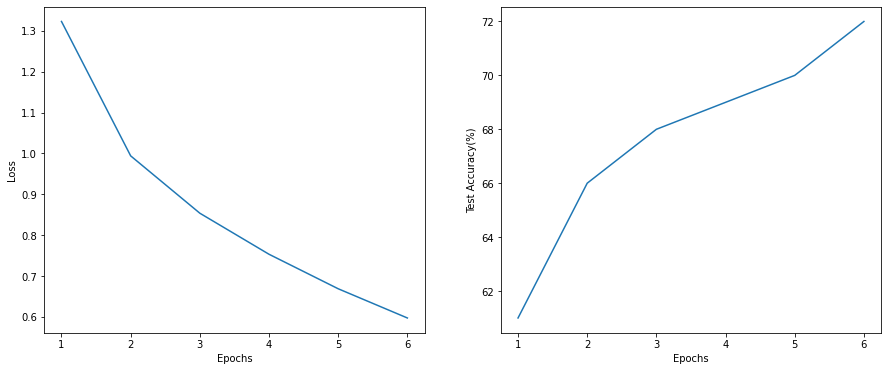

In [ ]:
plt.figure(figsize=(15,6))
plt.subplot(1, 2, 1)
plt.plot(range(1,len(train_loss_list)+1),train_loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")


plt.subplot(1, 2, 2)
plt.plot(range(1,num_epochs+1),test_acc_list)
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

Παρατηρούμε ότι η ακρίβεια βελτιώθηκε σημαντικά σε σχέση με το προηγούμενο δίκτυου που δεν είχε batch normalization

## Μετατρέπουμε το δίκτυο σε fully convolutional δίκτυο.

In [ ]:
class FCNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, 3)
        self.conv1_bn = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(64, 100, 3)
        self.conv1_bn = nn.BatchNorm2d(100)
        self.pool2 = nn.MaxPool2d(3, 2)
        self.conv3 = nn.Conv2d(100, 128, 3)
        self.conv4 = nn.Conv2d(128, 10, 3)

        self.pool3 = nn.MaxPool2d(2, 1)


    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = F.relu(self.conv3(x))
        x = self.pool3(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        return x


fcnet = FCNet()

Παρατηρούμε οτι οι παράμετροι του δικτύου έγιναν 186,350. Ακόμα και με την αυξηση των kernel στα δύο πρώτα επίπεδα και την εφαρμογή ακόμα 2 convolutional layer οι παράμετροι του δικτύου μειώθηκαν κατα 40%

In [ ]:
if torch.cuda.is_available():
  summary(fcnet.cuda() , (3,32,32))
else:
  summary(fcnet , (3,32,32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
         MaxPool2d-2           [-1, 64, 15, 15]               0
            Conv2d-3          [-1, 100, 13, 13]          57,700
         MaxPool2d-4            [-1, 100, 6, 6]               0
            Conv2d-5            [-1, 128, 4, 4]         115,328
            Conv2d-6             [-1, 10, 2, 2]          11,530
         MaxPool2d-7             [-1, 10, 1, 1]               0
Total params: 186,350
Trainable params: 186,350
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.72
Params size (MB): 0.71
Estimated Total Size (MB): 1.44
----------------------------------------------------------------



Ορίζουμε τον αριθμό εποχών,το learning rate,τον optimizer και το loss function για την εκπαίδευση.

In [ ]:
learning_rate = 0.001
num_epochs = 6


if torch.cuda.is_available():
  model = fcnet.cuda()
else:
  model = fcnet


loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(fcnet.parameters(), lr=learning_rate, momentum=0.9)

Εκπαιδεύουμε το δίκτυο

In [ ]:
test_acc_list = []
train_loss_list = []
for t in range(num_epochs):
  print(f"\nEpoch {t+1}\n-------------------------------")
  loss = train_loop(trainloader,fcnet,loss_fn,optimizer,t)
  acc = test_loop(testloader,fcnet)

  train_loss_list.append(loss)
  test_acc_list.append(acc)


Epoch 1
-------------------------------
Accuracy of the network on the 10000 test images: 36 %

Epoch 2
-------------------------------
Accuracy of the network on the 10000 test images: 52 %

Epoch 3
-------------------------------
Accuracy of the network on the 10000 test images: 57 %

Epoch 4
-------------------------------
Accuracy of the network on the 10000 test images: 61 %

Epoch 5
-------------------------------
Accuracy of the network on the 10000 test images: 65 %

Epoch 6
-------------------------------
Accuracy of the network on the 10000 test images: 65 %


Παρακάτω φαίνεται το διάγραμμα κόστους/εποχών και το διάγραμμα test accuracy/εποχών

<function matplotlib.pyplot.show(*args, **kw)>

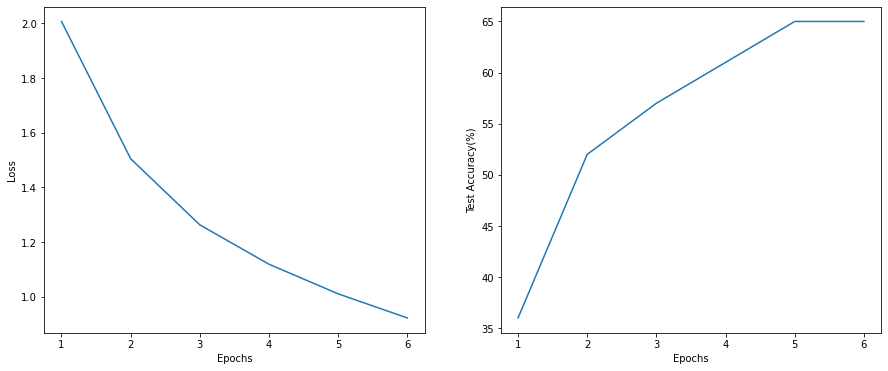

In [ ]:
plt.figure(figsize=(15,6))
plt.subplot(1, 2, 1)
plt.plot(range(1,len(train_loss_list)+1),train_loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")


plt.subplot(1, 2, 2)
plt.plot(range(1,num_epochs+1),test_acc_list)
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

## Δικο μου CNN

Από τα προηγούμενα δίκτυα θα εφαρμόσουμε σίγουρα το batch normalization αφού βελτίωσε την απόδοση του δικτύου αρκετά. Επιλέγουμε το δίκτυο μας να μην είναι fully convolutional αφού το προηγούμενο δίκτυο που ήταν fully convolutional δεν είχε ικανοποιητική απόδοση. Στο δικτυο με το batch normalization θα προσθέσουμε ένα hidden layer με 84 νευρώνες πριν την έξοδο. Επίσης θα αυξήσουμε τον αριθμό των kernel σε 100 και 128.

Έγιναν δοκιμές για διαφορετικά activation functions αλλά βρέθηκε οτι η relu παράγει καλύτερα και ταχύτερα αποτελέσματα από την tanh και την sigmoid στο συγκεκριμένο πρόβλημα. Επίσης, βρέθηκε οτι ο sgd optimizer υπερτερει του Adam.

Μία προσθηκη σε σχέση με τα προηγούμενα δίκτυα είναι η αλλαγή του maxpool που εφαρμόζεται μετα το δευτερο επίπεδο convolution. Αντι για 2x2 kernel έχουμε 3x3 kernel ωστε να λαμβάνονται υπόψιν όλα τα στοιχεία της (13x13) εικόνας.

In [ ]:
class myNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 100, 3)
        self.conv1_bn = nn.BatchNorm2d(100)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(100, 128, 3)
        self.conv2_bn = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(3, 2)
        self.fc1 = nn.Linear(128 * 6 * 6, 128)
        self.fc2 = nn.Linear(128, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1_bn(self.conv1(x))))
        x = self.pool2(F.relu(self.conv2_bn(self.conv2(x))))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


my_net = myNet()

In [ ]:
if torch.cuda.is_available():
  summary(my_net.cuda() , (3,32,32))
else:
  summary(my_net , (3,32,32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
       BatchNorm2d-2           [-1, 64, 30, 30]             128
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
       BatchNorm2d-5          [-1, 128, 13, 13]             256
         MaxPool2d-6            [-1, 128, 6, 6]               0
            Conv2d-7            [-1, 128, 4, 4]         147,584
       BatchNorm2d-8            [-1, 128, 4, 4]             256
         MaxPool2d-9            [-1, 128, 2, 2]               0
           Linear-10                  [-1, 128]          65,664
           Linear-11                   [-1, 84]          10,836
           Linear-12                   [-1, 10]             850
Total params: 301,222
Trainable params: 301,222
Non-trainable params: 0
-------------------------------

Ορίζουμε τον αριθμό εποχών,το learning rate,τον optimizer και το loss function για την εκπαίδευση.

In [ ]:
learning_rate = 0.001
num_epochs = 6

if torch.cuda.is_available():
  model = my_net.cuda()
else:
  model = my_net

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate,momentum=0.9)

Εκπαιδεύουμε το δίκτυο

In [ ]:
test_acc_list = []
train_loss_list = []
for t in range(num_epochs):
  print(f"\nEpoch {t+1}\n-------------------------------")
  loss = train_loop(trainloader,model,loss_fn,optimizer,t)
  acc = test_loop(testloader,model)

  train_loss_list.append(loss)
  test_acc_list.append(acc)


Epoch 1
-------------------------------
Accuracy of the network on the 10000 test images: 59 %

Epoch 2
-------------------------------
Accuracy of the network on the 10000 test images: 66 %

Epoch 3
-------------------------------
Accuracy of the network on the 10000 test images: 71 %

Epoch 4
-------------------------------
Accuracy of the network on the 10000 test images: 69 %

Epoch 5
-------------------------------
Accuracy of the network on the 10000 test images: 73 %

Epoch 6
-------------------------------
Accuracy of the network on the 10000 test images: 72 %


Παρακάτω φαίνεται το διάγραμμα κόστους/εποχών και το διάγραμμα test accuracy/εποχών

<function matplotlib.pyplot.show(*args, **kw)>

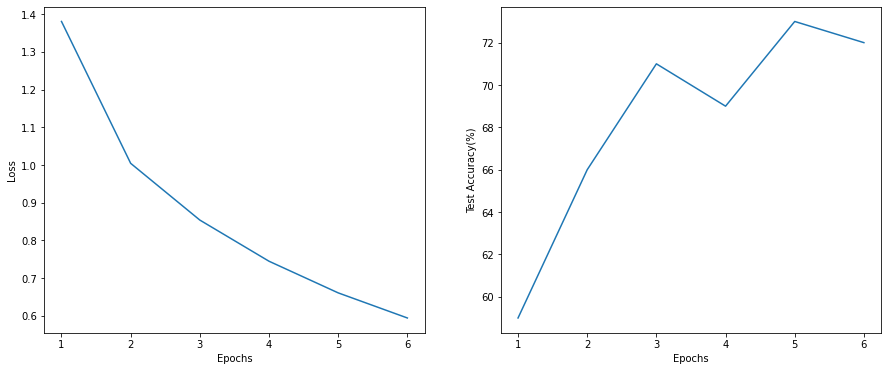

In [ ]:
plt.figure(figsize=(15,6))
plt.subplot(1, 2, 1)
plt.plot(range(1,len(train_loss_list)+1),train_loss_list)
plt.xlabel("Epochs")
plt.ylabel("Loss")


plt.subplot(1, 2, 2)
plt.plot(range(1,num_epochs+1),test_acc_list)
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy(%)")

plt.show

# 2ο Μέρος

In [ ]:
from sklearn.model_selection import train_test_split
from PIL import Image
import cv2
import os
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from matplotlib.pyplot import figure
import warnings
warnings.filterwarnings("ignore")

Ανεβάστε το αρχείο "Mask_DB.zip"

Γίνεται unzip το αρχείο

In [ ]:
from zipfile import ZipFile
file_name = '/content/Mask_DB.zip'

with ZipFile(file_name, 'r') as zip:
  zip.extractall()
  print('Done')

Done


Φορτώνουμε τις εκόνες στις λιστες dataset_with_mask και dataset_without_mask και ενώνουμε τις δύο λίστες για να σχηματίσουμε το dataset εκπαίδευσης

In [ ]:
def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        img = cv2.imread(os.path.join(folder,filename))
        if img is not None:
            images.append(img)
    return images

In [ ]:
dataset_with_mask = load_images_from_folder('/content/with_mask')
dataset_without_mask = load_images_from_folder('/content/without_mask')

In [ ]:
dataset = dataset_with_mask+dataset_without_mask
dataset = np.array(dataset)

Δημιουργία Labels για το dataset εκπαίδευσης

In [ ]:
labels0 = [0] * 1044
labels1 = [1] * 1044
labels = labels0 + labels1

## Διαχωρισμός Δεδομένων σε Train, Validation και Test

In [ ]:
data_flat = np.array(dataset).reshape((2088, 32*32*3))

In [ ]:
train_data, testVal_data, train_labels, testVal_labels = train_test_split(data_flat, labels, test_size=0.4,random_state = None)

In [ ]:
test_data, val_data, test_labels, val_labels = train_test_split(testVal_data, testVal_labels, test_size=0.5,random_state = None)

## Υλοποίηση συστήματος αναγνώρισης προτύπων με εφαρμογή PCA για ελάττωση διαστάσεων και νευρωνικό δίκτυο τριων κρυφών επιπέδων για ταξινόμηση

Ελάττωση διαστάσεων με PCA. Αρχικά θα δοκιμάσουμε ελάττωση σε 100 διαστάσεις από τις 32x32x3 = 3.072 αρχικές διαστάσεις

In [ ]:
pca = PCA(n_components=100)
X_reduced = pca.fit_transform(train_data)

Ο λόγος που επιλέγουμε το PCA για μείωση διαστάσεων είναι επειδή μπορούμε να συγκρατήσουμε μεγάλο μέρος της πληροφορίας μειώνοντας αρκετα τις διαστάσεις. Με ελάττωση διαστάσεων από 3,072 σε 100  μπορέσαμε να κρατήσουμε το % του variance των αρχικών εικόνων

In [ ]:
print(pca.explained_variance_ratio_)

[0.29542824 0.13705683 0.07960666 0.05583721 0.04919765 0.02564677
 0.02146153 0.01942695 0.01466646 0.0138636  0.01228794 0.01018228
 0.00960794 0.00837628 0.00760348 0.00701871 0.00636087 0.00615544
 0.00572317 0.00568453 0.00542166 0.00486606 0.00474702 0.0045006
 0.00431326 0.00418275 0.00404766 0.003847   0.00368984 0.00349863
 0.00332008 0.00317848 0.00299867 0.00287089 0.00279551 0.00275915
 0.00257735 0.00252318 0.00244828 0.00239284 0.00233184 0.00227602
 0.00219634 0.00216697 0.00208833 0.00206734 0.00198692 0.00196207
 0.00190551 0.00185221 0.00171181 0.00168802 0.00164695 0.0016191
 0.00160151 0.00158339 0.0015125  0.00148339 0.00144118 0.00143203
 0.00137943 0.00135429 0.00129993 0.00127511 0.00124423 0.00122772
 0.00122344 0.00117023 0.00115682 0.00112072 0.00109822 0.00107938
 0.00105886 0.0010401  0.00103535 0.00098563 0.00097624 0.00095612
 0.00094587 0.00091962 0.00090805 0.00088334 0.00086843 0.00084529
 0.00083624 0.00081418 0.00080343 0.00079616 0.00078814 0.000782

Ταξινόμηση με νευρωνικό δίκτυο 3ων κρυφών επιπέδων με 30,20,20 νευρώνες και συνάρτηση ενεργοποίησης tanh. Καταλήξαμε στο συγκεκριμένο δίκτυο με δοκιμές.

In [ ]:
Classifier = MLPClassifier( activation='tanh',solver='adam', alpha=1e-5,max_iter=300, hidden_layer_sizes=(30, 20, 20))
Classifier.fit(X_reduced, train_labels)

MLPClassifier(activation='tanh', alpha=1e-05, hidden_layer_sizes=(30, 20, 20),
              max_iter=300)

##Επιλογή βελτιστου αριθμού διαστάσεων

In [ ]:
dimensions_to_try = [2] + list(range(5,101,5))
print("We will try the following dimensions: "+ str(dimensions_to_try))

We will try the following dimensions: [2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]


In [ ]:
best_num_of_dim = 0
best_val_acc = 0
validation_scores = []
print("Dimensions tried:\n")
for dimensions in dimensions_to_try:

  pca = PCA(n_components=dimensions)
  Train_fewdim = pca.fit_transform(train_data)

  Val_accuracy = 0
  times_to_try = 3
  for i in range(0,times_to_try):
    Classifier = MLPClassifier( activation='tanh',solver='adam', alpha=1e-5,max_iter=300, hidden_layer_sizes=(30, 20, 20))
    Classifier.fit(Train_fewdim, train_labels)

    Val_fewdim = pca.transform(val_data)
    predictions = Classifier.predict(Val_fewdim)
    val_acc = accuracy_score(val_labels, predictions)

    Val_accuracy += val_acc

  Val_accuracy = Val_accuracy/times_to_try
  if Val_accuracy >= best_val_acc:
    best_val_acc = Val_accuracy
    best_num_of_dim = dimensions

  validation_scores.append(Val_accuracy)

  print(str(dimensions),end='  ')

print("Best number of dimensions is "+str(best_num_of_dim))
print("\nWe trained "+str(times_to_try)+" classifiers for each dimension and calculated their average validation accuracy")
print("\nAverage validation accuracy for "+str(best_num_of_dim)+" dimensions is "+str(round(100*best_val_acc,2))+"%")


Dimensions tried:

2  5  10  15  20  25  30  35  40  45  50  55  60  65  70  75  80  85  90  95  100  Best number of dimensions is 10

We trained 3 classifiers for each dimension and calculated their average validation accuracy

Average validation accuracy for 10 dimensions is 93.62%


Το διάγραμμα δείχνει το validation accuracy σε συνάρτηση με τις διαστάσεις

Text(0, 0.5, 'Validation Accuracy (%)')

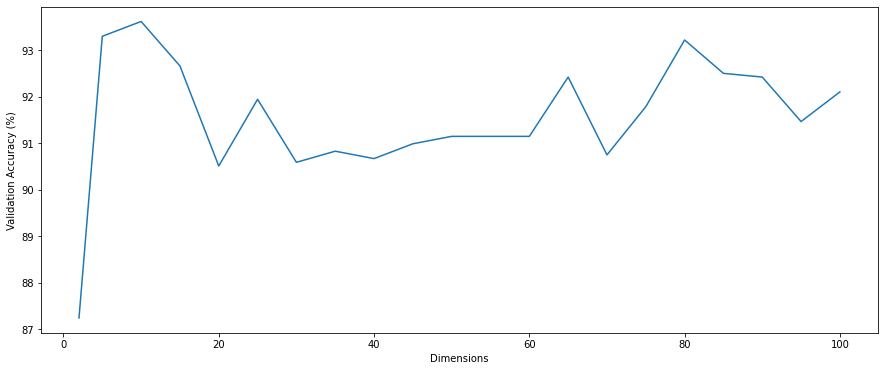

In [ ]:
plt.figure(figsize=(15,6))
plt.plot(dimensions_to_try,[i*100 for i in validation_scores])
plt.xlabel("Dimensions")
plt.ylabel("Validation Accuracy (%)")

Ακρίβεια του μοντέλου στα test δεδομένα

In [ ]:
pca = PCA(n_components=best_num_of_dim)
Train_fewdim = pca.fit_transform(train_data)

In [ ]:
Classifier = MLPClassifier( activation='tanh',solver='adam', alpha=1e-5,max_iter=300, hidden_layer_sizes=(30, 20, 20))
Classifier.fit(Train_fewdim, train_labels)

MLPClassifier(activation='tanh', alpha=1e-05, hidden_layer_sizes=(30, 20, 20),
              max_iter=300)

In [ ]:
Test_fewdim = pca.transform(test_data)

predictions = Classifier.predict(Test_fewdim)

print("accuracy: " + str(round(100*accuracy_score(test_labels, predictions),2))+"%")

accuracy: 92.82%


Εφαρμογή μοντέλου σε εικόνες της κλάσης «mask_incorrect_use»

In [ ]:
dataset_incorrect_use = load_images_from_folder('/content/mask_incorrect_use')

data_incorrect = np.array(dataset_incorrect_use).reshape((len(dataset_incorrect_use), 32*32*3))

In [ ]:
labels_incorrect = [0] * len(dataset_incorrect_use)

Πόσοστό εικόνων που ταξινομήθηκαν στην κατηγορία αποδεκτή χρήση μάσκας.

In [ ]:
data_incorrect_fewdim = pca.transform(data_incorrect)

predictions = Classifier.predict(data_incorrect_fewdim)

print("Percentage of «mask_incorrect_use» images that are labeled in «with_mask» class:  " + str(round(100*(accuracy_score(labels_incorrect, predictions)),2))+" %")

Percentage of «mask_incorrect_use» images that are labeled in «with_mask» class:  85.71 %


## Πρόταση τρόπων που μπορει να αυξηθεί ο αριθμός των εικόνων της κλάσης mask_incorrect_use που ταξινομούνται ως μη αποδεκτή χρήση μάσκας

### Τρόπος 1

Ενταξη μέρους του dataset "mask_incorrect_use" στο dataset εκπαίδευσης. Επειδή οι εικονες που βρίσκονται στο "mask_incorrect_use" είναι λίγες, μπορούμε να εφαρμόσουμε data augmentation για να τις αυξησουμε

### Τρόπος 2

Αν έχουμε πρόσβαση σε εξωτερικά παρόμοια δεδομένα με αυτά της κλάσης "mask incorrect use", μπορουμε να εκπαιδευσουμε ενα δίκτυο με αυτα τα δεδομενα και στην συνέχεια να περάσουμε τους συντελεστές αυτού του δικτύου στο τελικό μας δίκτυο πριν ξεκινήσουμε την εκπαίδευση